# XAUUSD D1 — N-Method Strategy Backtest

This notebook implements and backtests three operational interpretations of the N-Method pattern on daily XAUUSD OHLCV data:

1. **Bullish N:** swing low (P1) → swing high (P2) → higher swing low (P3); place a buy-stop above P2.
2. **Bearish N:** swing high (P1) → swing low (P2) → lower swing high (P3); place a sell-stop below P2.
3. **Ranging N:** identify two tests of a similar resistance area and two tests of a similar support area; place opposing breakout orders using one-cancels-the-other (OCO) logic.

The default reward-to-risk ratio is **2:1 (2R target for each 1R of initial risk)**.

## Important note on rule interpretation

This notebook is a research implementation, **not a verified reproduction of an official or proprietary Traders Family rulebook**. The complete public rule set for all three variations, especially stop-loss placement, has not been independently verified. Stop-loss logic is therefore operationalized using general chart-pattern guidance:

- For swing/pullback structures, place the stop beyond the relevant P3 swing.
- For range breakouts, place the stop beyond the opposite range boundary.

Reference: [Traders Family — 3 Jenis Utama Chart Pattern dalam Trading](https://tradersfamily.id/3-jenis-utama-chart-pattern-dalam-trading/). The article provides general chart-pattern guidance; it should not be interpreted as proof that every rule in this notebook matches a proprietary N-Method specification.

**Research warning:** backtest results are simulated and do not imply future performance. Spread, commission, swap, broker-specific contract specifications, and realistic slippage are not fully modeled. This notebook is not a live-trading recommendation.


In [ ]:

from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# -----------------------------
# 1. Load and normalize OHLCV
# -----------------------------
def load_ohlcv(path: str) -> pd.DataFrame:
    """
    Reads the supplied TradingView-style CSV.
    The uploaded file has NO header row:
    Date, Open, High, Low, Close, Volume.
    """
    raw = pd.read_csv(path, header=None)
    if raw.shape[1] < 5:
        raise ValueError("CSV must contain at least Date, Open, High, Low, and Close columns.")

    names = ["Date", "Open", "High", "Low", "Close"]
    if raw.shape[1] >= 6:
        names.append("Volume")
    raw = raw.iloc[:, :len(names)].copy()
    raw.columns = names

    raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")
    for c in ["Open", "High", "Low", "Close"]:
        raw[c] = pd.to_numeric(raw[c], errors="coerce")
    if "Volume" in raw:
        raw["Volume"] = pd.to_numeric(raw["Volume"], errors="coerce")

    raw = (raw.dropna(subset=["Date", "Open", "High", "Low", "Close"])
              .sort_values("Date")
              .drop_duplicates("Date")
              .set_index("Date"))

    # Basic data validation
    invalid = (raw["High"] < raw[["Open", "Close", "Low"]].max(axis=1)) | (
        raw["Low"] > raw[["Open", "Close", "High"]].min(axis=1)
    )
    if invalid.any():
        raise ValueError(f"Found {invalid.sum()} invalid OHLC bars.")

    return raw


# Resolve the project root whether the notebook is launched from the repository root or /notebooks.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "XAUUSD_D1.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df = load_ohlcv(str(DATA_PATH))

print(f"Rows: {len(df):,}")
print(f"Period: {df.index.min().date()} to {df.index.max().date()}")
display(df.head())


Rows: 5,221
Period: 2010-02-01 to 2026-11-11


,Open,High,Low,Close,Volume
Date,,,,,
2010-02-01,1078.887,1107.084,1076.047,1103.854,1237
2010-02-02,1103.766,1117.679,1098.554,1114.676,1418
2010-02-03,1115.115,1124.254,1106.783,1108.657,1418
2010-02-04,1108.507,1110.442,1059.334,1064.238,1422
2010-02-05,1064.293,1068.206,1044.703,1065.619,1315


In [ ]:

# -----------------------------
# 2. Indicators and confirmed swing points
# -----------------------------
def add_atr(data: pd.DataFrame, period: int = 14) -> pd.DataFrame:
    out = data.copy()
    prev_close = out["Close"].shift(1)
    tr = pd.concat([
        out["High"] - out["Low"],
        (out["High"] - prev_close).abs(),
        (out["Low"] - prev_close).abs()
    ], axis=1).max(axis=1)
    out["ATR"] = tr.rolling(period, min_periods=period).mean()
    return out


def confirmed_pivots(data: pd.DataFrame, left: int = 3, right: int = 3) -> list[dict]:
    """
    Pivot is only made available at its confirmation bar (center + right).
    This avoids using future bars before the pivot is confirmed.
    """
    pivots = []
    for confirm_i in range(left + right, len(data)):
        center_i = confirm_i - right
        start_i = center_i - left
        end_i = center_i + right
        window = data.iloc[start_i:end_i + 1]

        center_high = data["High"].iloc[center_i]
        center_low = data["Low"].iloc[center_i]

        if center_high >= window["High"].max():
            # Tie handling: accept only if the center is the last occurrence of max.
            if np.flatnonzero(window["High"].to_numpy() == center_high)[-1] == left:
                pivots.append({
                    "type": "H", "pivot_i": center_i, "confirm_i": confirm_i,
                    "price": float(center_high), "date": data.index[center_i]
                })

        if center_low <= window["Low"].min():
            if np.flatnonzero(window["Low"].to_numpy() == center_low)[-1] == left:
                pivots.append({
                    "type": "L", "pivot_i": center_i, "confirm_i": confirm_i,
                    "price": float(center_low), "date": data.index[center_i]
                })

    return sorted(pivots, key=lambda x: (x["confirm_i"], x["pivot_i"]))


data = add_atr(df)
pivots = confirmed_pivots(data, left=3, right=3)
print(f"Confirmed pivots: {len(pivots):,}")


Confirmed pivots: 989


In [ ]:

# -----------------------------
# 3. Shared backtest engine
# -----------------------------
def _backtest_setups(
    data: pd.DataFrame,
    setups: list[dict],
    rr: float = 2.0,
    expiry_bars: int = 20,
    one_position_at_a_time: bool = True,
) -> pd.DataFrame:
    """
    Each setup:
      signal_i: bar index when setup becomes known
      orders: list of {side: 'long'/'short', entry, sl, tag}
      setup_type: bullish / bearish / ranging

    Entry is a stop-entry order and becomes active from the NEXT daily bar.
    For ranging setups, orders are OCO: once one side triggers, the other is cancelled.
    If SL and TP are both touched in the same daily candle, SL is assumed first
    (conservative OHLC-only assumption).
    """
    trades = []
    busy_until = -1
    n = len(data)

    for setup in sorted(setups, key=lambda x: x["signal_i"]):
        signal_i = int(setup["signal_i"])
        if signal_i + 1 >= n:
            continue
        if one_position_at_a_time and signal_i <= busy_until:
            continue

        active_from = signal_i + 1
        last_i = min(n - 1, active_from + expiry_bars - 1)
        triggered = False

        for i in range(active_from, last_i + 1):
            bar = data.iloc[i]
            orders_hit = []

            for order in setup["orders"]:
                side, entry, sl = order["side"], float(order["entry"]), float(order["sl"])

                # A stop-entry is triggered by intraday high/low.
                hit = (bar["High"] >= entry) if side == "long" else (bar["Low"] <= entry)
                if hit:
                    # Gap-aware stop entry.
                    fill = max(entry, float(bar["Open"])) if side == "long" else min(entry, float(bar["Open"]))
                    # Skip malformed orders.
                    if (side == "long" and sl >= fill) or (side == "short" and sl <= fill):
                        continue
                    risk = abs(fill - sl)
                    tp = fill + rr * risk if side == "long" else fill - rr * risk
                    orders_hit.append({
                        "side": side, "entry": fill, "sl": sl, "tp": tp,
                        "risk": risk, "tag": order.get("tag", "")
                    })

            if not orders_hit:
                continue

            # In a range OCO setup, if both boundaries are hit on the same D1 bar,
            # daily OHLC cannot reveal which came first. Skip the ambiguous signal.
            if len(orders_hit) > 1:
                trades.append({
                    "setup": setup["setup_type"], "side": "ambiguous",
                    "signal_date": data.index[signal_i], "entry_date": data.index[i],
                    "entry": np.nan, "sl": np.nan, "tp": np.nan,
                    "exit_date": data.index[i], "exit": np.nan,
                    "result": "AMBIGUOUS_BOTH_SIDES", "R": 0.0,
                    "bars_held": 0, "pattern": setup.get("pattern", "")
                })
                triggered = True
                busy_until = i
                break

            order = orders_hit[0]
            side, entry, sl, tp, risk = (
                order["side"], order["entry"], order["sl"], order["tp"], order["risk"]
            )

            # Evaluate the entry bar too: conservative stop-first if both SL and TP touched.
            exit_price, result, exit_i = None, None, None
            for j in range(i, n):
                b = data.iloc[j]
                if side == "long":
                    sl_hit = b["Low"] <= sl
                    tp_hit = b["High"] >= tp
                    if sl_hit:
                        exit_price, result, exit_i = (min(sl, float(b["Open"])) if b["Open"] < sl else sl), "SL", j
                        break
                    if tp_hit:
                        exit_price, result, exit_i = (max(tp, float(b["Open"])) if b["Open"] > tp else tp), "TP", j
                        break
                else:
                    sl_hit = b["High"] >= sl
                    tp_hit = b["Low"] <= tp
                    if sl_hit:
                        exit_price, result, exit_i = (max(sl, float(b["Open"])) if b["Open"] > sl else sl), "SL", j
                        break
                    if tp_hit:
                        exit_price, result, exit_i = (min(tp, float(b["Open"])) if b["Open"] < tp else tp), "TP", j
                        break

            if exit_i is None:
                exit_i = n - 1
                exit_price = float(data["Close"].iloc[-1])
                result = "OPEN_AT_END"

            pnl_points = (exit_price - entry) if side == "long" else (entry - exit_price)
            r_multiple = pnl_points / risk if risk > 0 else np.nan

            trades.append({
                "setup": setup["setup_type"], "side": side,
                "signal_date": data.index[signal_i], "entry_date": data.index[i],
                "entry": entry, "sl": sl, "tp": tp,
                "exit_date": data.index[exit_i], "exit": exit_price,
                "result": result, "R": r_multiple,
                "bars_held": exit_i - i + 1,
                "pattern": setup.get("pattern", "")
            })
            triggered = True
            busy_until = exit_i
            break

        # If no order was triggered, the setup simply expires.
    return pd.DataFrame(trades)


def _summarize(trades: pd.DataFrame) -> pd.Series:
    if trades.empty:
        return pd.Series({"Trades": 0, "Win rate %": np.nan, "Net R": 0.0,
                          "Profit factor (R)": np.nan, "Avg R": np.nan,
                          "Max consecutive losses": 0})
    valid = trades[trades["result"].isin(["TP", "SL", "OPEN_AT_END"])].copy()
    wins = valid[valid["R"] > 0]
    losses = valid[valid["R"] < 0]
    gross_profit = wins["R"].sum()
    gross_loss = abs(losses["R"].sum())
    is_closed = valid["result"].isin(["TP", "SL"])
    loss_streak = max_streak = 0
    for is_loss in (valid.loc[is_closed, "R"] < 0):
        loss_streak = loss_streak + 1 if is_loss else 0
        max_streak = max(max_streak, loss_streak)
    return pd.Series({
        "Trades": len(valid),
        "Win rate %": 100 * (valid["R"] > 0).mean() if len(valid) else np.nan,
        "Net R": valid["R"].sum(),
        "Profit factor (R)": gross_profit / gross_loss if gross_loss else np.inf,
        "Avg R": valid["R"].mean() if len(valid) else np.nan,
        "Max consecutive losses": max_streak
    })


In [ ]:

# -----------------------------
# 4. Three N-method functions
# -----------------------------
def n_method_bullish(
    data: pd.DataFrame,
    left: int = 3,
    right: int = 3,
    rr: float = 2.0,
    entry_buffer_atr: float = 0.05,
    sl_buffer_atr: float = 0.05,
    expiry_bars: int = 20,
) -> pd.DataFrame:
    """
    Bullish N (continuation):
      P1 = confirmed swing low
      P2 = confirmed swing high
      P3 = higher swing low
      Entry = buy stop above P2
      SL = below P3 (outside the pullback structure)
      TP = 2R
    """
    d = add_atr(data) if "ATR" not in data else data.copy()
    ps = confirmed_pivots(d, left, right)
    setups = []

    for k in range(2, len(ps)):
        p1, p2, p3 = ps[k-2:k+1]
        if [p1["type"], p2["type"], p3["type"]] != ["L", "H", "L"]:
            continue
        if not (p3["price"] > p1["price"] and p2["price"] > p1["price"]):
            continue
        signal_i = p3["confirm_i"]
        atr = d["ATR"].iloc[signal_i]
        if not np.isfinite(atr) or atr <= 0:
            continue
        entry = p2["price"] + entry_buffer_atr * atr
        sl = p3["price"] - sl_buffer_atr * atr
        if sl >= entry:
            continue
        setups.append({
            "signal_i": signal_i, "setup_type": "bullish",
            "orders": [{"side": "long", "entry": entry, "sl": sl, "tag": "P2 breakout"}],
            "pattern": f"P1={p1['price']:.2f}; P2={p2['price']:.2f}; P3={p3['price']:.2f}"
        })

    return _backtest_setups(d, setups, rr=rr, expiry_bars=expiry_bars)


def n_method_bearish(
    data: pd.DataFrame,
    left: int = 3,
    right: int = 3,
    rr: float = 2.0,
    entry_buffer_atr: float = 0.05,
    sl_buffer_atr: float = 0.05,
    expiry_bars: int = 20,
) -> pd.DataFrame:
    """
    Bearish N (continuation):
      P1 = confirmed swing high
      P2 = confirmed swing low
      P3 = lower swing high
      Entry = sell stop below P2
      SL = above P3 (outside the pullback structure)
      TP = 2R
    """
    d = add_atr(data) if "ATR" not in data else data.copy()
    ps = confirmed_pivots(d, left, right)
    setups = []

    for k in range(2, len(ps)):
        p1, p2, p3 = ps[k-2:k+1]
        if [p1["type"], p2["type"], p3["type"]] != ["H", "L", "H"]:
            continue
        if not (p3["price"] < p1["price"] and p2["price"] < p1["price"]):
            continue
        signal_i = p3["confirm_i"]
        atr = d["ATR"].iloc[signal_i]
        if not np.isfinite(atr) or atr <= 0:
            continue
        entry = p2["price"] - entry_buffer_atr * atr
        sl = p3["price"] + sl_buffer_atr * atr
        if sl <= entry:
            continue
        setups.append({
            "signal_i": signal_i, "setup_type": "bearish",
            "orders": [{"side": "short", "entry": entry, "sl": sl, "tag": "P2 breakdown"}],
            "pattern": f"P1={p1['price']:.2f}; P2={p2['price']:.2f}; P3={p3['price']:.2f}"
        })

    return _backtest_setups(d, setups, rr=rr, expiry_bars=expiry_bars)


def n_method_ranging(
    data: pd.DataFrame,
    left: int = 3,
    right: int = 3,
    rr: float = 2.0,
    entry_buffer_atr: float = 0.05,
    sl_buffer_atr: float = 0.05,
    range_tolerance_atr: float = 0.50,
    expiry_bars: int = 20,
) -> pd.DataFrame:
    """
    Ranging N (two-sided breakout / OCO):
      Requires alternating confirmed pivots with two highs and two lows.
      The second high must not materially exceed the first high;
      the second low must not materially break the first low.
      Buy stop above range high; sell stop below range low.
      SL for each side is beyond the opposite side of the range.
      Once one side triggers, the other side is cancelled.
    """
    d = add_atr(data) if "ATR" not in data else data.copy()
    ps = confirmed_pivots(d, left, right)
    setups = []

    for k in range(3, len(ps)):
        q = ps[k-3:k+1]
        types = [x["type"] for x in q]
        if types not in (["H", "L", "H", "L"], ["L", "H", "L", "H"]):
            continue

        highs = [x["price"] for x in q if x["type"] == "H"]
        lows = [x["price"] for x in q if x["type"] == "L"]
        signal_i = q[-1]["confirm_i"]
        atr = d["ATR"].iloc[signal_i]
        if not np.isfinite(atr) or atr <= 0:
            continue

        range_high, range_low = max(highs), min(lows)
        # Confirm a bounded range: second test stays within tolerance of first.
        high_ok = abs(highs[1] - highs[0]) <= range_tolerance_atr * atr
        low_ok = abs(lows[1] - lows[0]) <= range_tolerance_atr * atr
        if not (high_ok and low_ok and range_high > range_low):
            continue

        entry_buy = range_high + entry_buffer_atr * atr
        sl_buy = range_low - sl_buffer_atr * atr
        entry_sell = range_low - entry_buffer_atr * atr
        sl_sell = range_high + sl_buffer_atr * atr

        setups.append({
            "signal_i": signal_i, "setup_type": "ranging",
            "orders": [
                {"side": "long", "entry": entry_buy, "sl": sl_buy, "tag": "range high breakout"},
                {"side": "short", "entry": entry_sell, "sl": sl_sell, "tag": "range low breakdown"},
            ],
            "pattern": f"RangeLow={range_low:.2f}; RangeHigh={range_high:.2f}"
        })

    return _backtest_setups(d, setups, rr=rr, expiry_bars=expiry_bars)


# Run all three methods on D1 data
bullish_trades = n_method_bullish(data)
bearish_trades = n_method_bearish(data)
ranging_trades = n_method_ranging(data)

summary = pd.DataFrame({
    "Bullish N": _summarize(bullish_trades),
    "Bearish N": _summarize(bearish_trades),
    "Ranging N": _summarize(ranging_trades),
}).T

display(summary)


,Trades,Win rate %,Net R,Profit factor (R),Avg R,Max consecutive losses
Bullish N,74.0,41.891892,18.873355,1.437626,0.255045,9.0
Bearish N,56.0,28.571429,-10.444257,0.747526,-0.186505,8.0
Ranging N,16.0,37.500000,0.028636,1.002864,0.001790,3.0


In [ ]:

# -----------------------------
# 5. Inspect and export results
# -----------------------------
all_trades = pd.concat([
    bullish_trades, bearish_trades, ranging_trades
], ignore_index=True).sort_values(["entry_date", "setup"], na_position="last")

display(all_trades.tail(20))

# Export trade-level results for further analysis in Excel / Python.
all_trades.to_csv(OUTPUT_DIR / "XAUUSD_D1_N_method_trades.csv", index=False)
summary.to_csv(OUTPUT_DIR / "XAUUSD_D1_N_method_summary.csv")
print("Exported: outputs/XAUUSD_D1_N_method_trades.csv")
print("Exported: outputs/XAUUSD_D1_N_method_summary.csv")


,setup,side,signal_date,entry_date,entry,sl,tp,exit_date,exit,result,R,bars_held,pattern
123,bearish,short,2024-02-11,2024-02-12,2013.955321,2045.344679,1951.176607,2024-02-29,2045.344679,SL,-1.000000,16,P1=2065.35; P2=2014.84; P3=2044.46
62,bullish,long,2024-02-08,2024-03-01,2066.302011,2013.880989,2171.144054,2024-03-08,2171.144054,TP,2.000000,7,P1=2009.45; P2=2065.35; P3=2014.84
63,bullish,long,2024-03-15,2024-03-20,2196.364000,2149.176000,2290.740000,2024-04-03,2290.740000,TP,2.000000,12,P1=2024.36; P2=2195.09; P3=2150.45
124,bearish,short,2024-04-23,2024-04-24,2321.601025,2420.001975,2124.799125,2024-05-17,2420.001975,SL,-1.000000,21,P1=2431.39; P2=2323.86; P3=2417.74
125,bearish,short,2024-05-31,2024-06-02,2323.699514,2365.540486,2240.017571,2024-06-06,2365.540486,SL,-1.000000,5,P1=2449.99; P2=2325.26; P3=2363.97
64,bullish,long,2024-08-08,2024-08-14,2479.515568,2362.142432,2714.261839,2024-10-18,2714.261839,TP,2.000000,57,P1=2353.01; P2=2477.49; P3=2364.16
65,bullish,long,2024-10-27,2024-10-29,2759.617089,2707.355911,2864.139446,2024-11-06,2707.355911,SL,-1.000000,8,P1=2601.73; P2=2758.34; P3=2708.64
66,bullish,long,2024-11-28,2024-12-12,2723.124371,2603.145629,2963.081857,2024-12-18,2603.145629,SL,-1.000000,6,P1=2536.66; P2=2721.18; P3=2605.09
126,bearish,short,2024-12-03,2024-12-18,2603.255196,2668.024804,2473.715982,2025-01-08,2668.024804,SL,-1.000000,19,P1=2721.18; P2=2605.09; P3=2666.20
67,bullish,long,2025-01-02,2025-01-03,2658.275000,2594.653779,2785.517443,2025-01-24,2785.517443,TP,2.000000,19,P1=2582.26; P2=2638.97; P3=2595.91


Exported: outputs/XAUUSD_D1_N_method_trades.csv
Exported: outputs/XAUUSD_D1_N_method_summary.csv


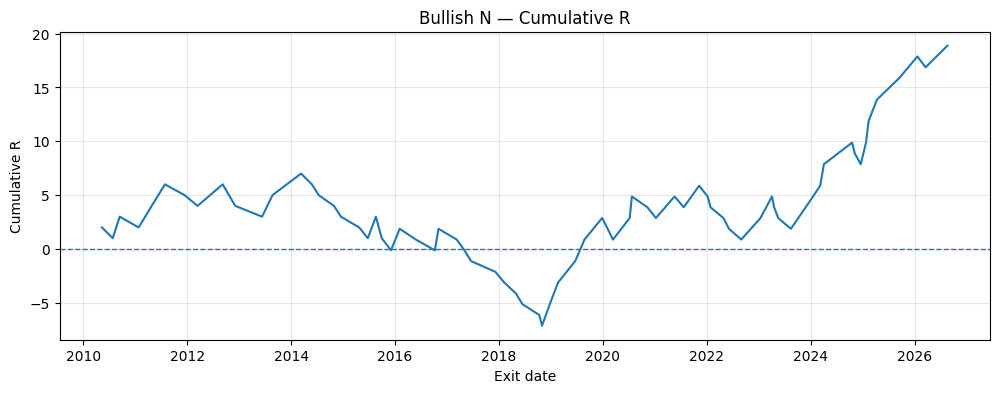

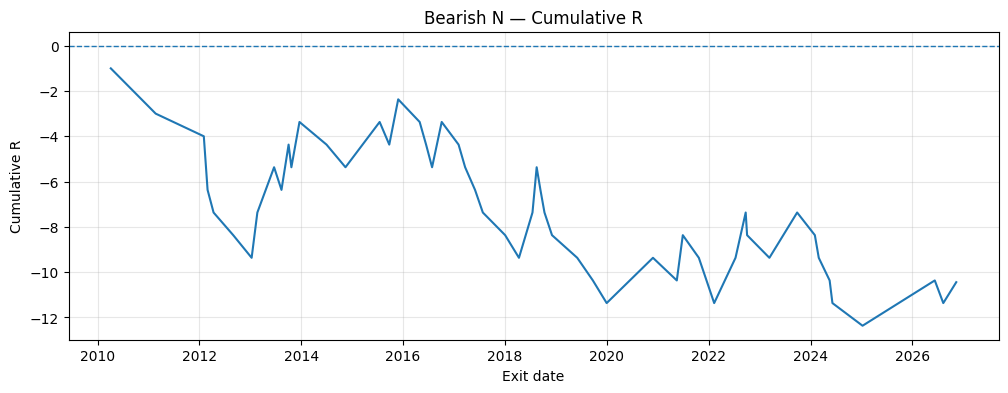

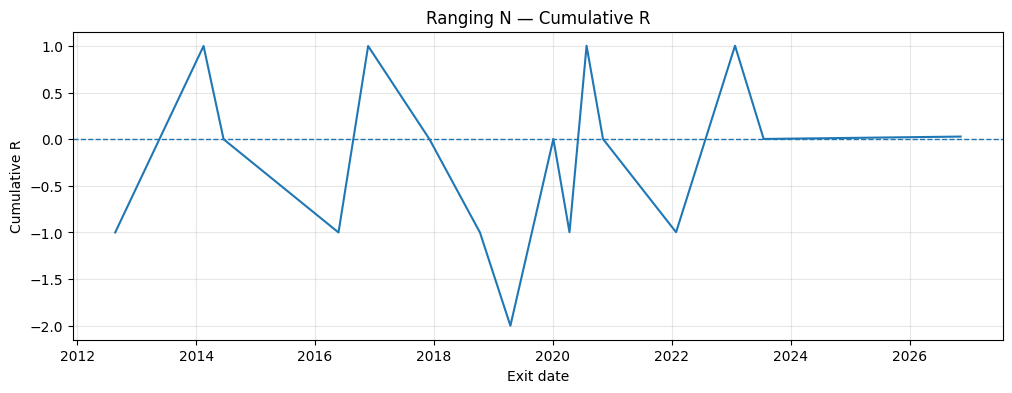

In [ ]:

# -----------------------------
# 6. Visualize cumulative R
# -----------------------------
for label, trades in [
    ("Bullish N", bullish_trades),
    ("Bearish N", bearish_trades),
    ("Ranging N", ranging_trades),
]:
    valid = trades[trades["result"].isin(["TP", "SL", "OPEN_AT_END"])].copy()
    if valid.empty:
        print(f"{label}: no trades")
        continue
    valid = valid.sort_values("exit_date")
    plt.figure(figsize=(12, 4))
    plt.plot(valid["exit_date"], valid["R"].cumsum())
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.title(f"{label} — Cumulative R")
    plt.xlabel("Exit date")
    plt.ylabel("Cumulative R")
    plt.grid(True, alpha=0.3)
    plt.show()


In [ ]:

# -----------------------------
# 7. Assumptions and limitations
# -----------------------------
print("""
IMPORTANT BACKTEST ASSUMPTIONS
1. The CSV is treated as D1 OHLCV data, with Date/Open/High/Low/Close/Volume columns.
2. A swing pivot is only known after `right` bars have closed; no pivot look-ahead is used.
3. Entry is a stop order active from the bar after the setup is confirmed.
4. Orders expire after `expiry_bars` daily candles.
5. Ranging uses OCO logic. If both range boundaries are crossed in the same daily candle,
   the result is marked ambiguous and excluded from performance statistics.
6. If SL and TP are both touched in one daily candle, SL is assumed first (conservative).
7. Spread, commission, swap, slippage beyond gap-aware fills, and broker-specific contract
   specifications are NOT included.
8. RR is fixed at 1:2, with TP calculated from the actual entry-to-SL distance.
9. The SL logic is a practical interpretation of Traders Family's published general guidance:
   use the nearest swing low/high for reversal structures and the outer boundary of a
   consolidation for continuation/breakout structures. It is not a verified reproduction
   of a proprietary N-method rulebook. Validate against the original lesson/material.
10. This is research code, not a recommendation to trade live.
""")



IMPORTANT BACKTEST ASSUMPTIONS
1. The CSV is treated as D1 OHLCV data, with Date/Open/High/Low/Close/Volume columns.
2. A swing pivot is only known after `right` bars have closed; no pivot look-ahead is used.
3. Entry is a stop order active from the bar after the setup is confirmed.
4. Orders expire after `expiry_bars` daily candles.
5. Ranging uses OCO logic. If both range boundaries are crossed in the same daily candle,
   the result is marked ambiguous and excluded from performance statistics.
6. If SL and TP are both touched in one daily candle, SL is assumed first (conservative).
7. Spread, commission, swap, slippage beyond gap-aware fills, and broker-specific contract
   specifications are NOT included.
8. RR is fixed at 1:2, with TP calculated from the actual entry-to-SL distance.
9. The SL logic is a practical interpretation of Traders Family's published general guidance:
   use the nearest swing low/high for reversal structures and the outer boundary of a
   consolidation for

## Configurable parameters

- `left=3`, `right=3`: swing/pivot sensitivity. A pivot becomes available only after three bars on its right have closed.
- `entry_buffer_atr=0.05`: entry buffer, expressed as 0.05 ATR beyond the breakout level.
- `sl_buffer_atr=0.05`: stop-loss buffer, expressed as 0.05 ATR beyond the relevant structure.
- `range_tolerance_atr=0.50`: maximum difference between the two tests of each range boundary, measured in ATR.
- `expiry_bars=20`: pending orders expire after 20 daily candles.
- `rr=2.0`: take-profit target is 2R.

For stronger evidence, perform parameter sensitivity analysis, out-of-sample testing, and walk-forward validation, and incorporate broker-specific transaction costs. Avoid selecting parameters solely because they produce the best historical equity curve across the full sample.
